# 02 — Preprocessing, modeling, dan evaluasi
Baseline adalah CNN PyTorch dari awal, diikuti opsi fine-tuning EfficientNet-B0. Gunakan split yang sama untuk perbandingan. Semua metrik yang ditampilkan berasal dari artefak training, bukan angka perkiraan.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
assert (ROOT / 'scripts').is_dir(), 'Buka notebook dari root proyek atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.preprocess import data_directory, read_metadata
DATA = data_directory()
train, test, sample = read_metadata(DATA)

## Konfigurasi dan perangkat
CNN baseline menggunakan 128×128 grayscale, empat blok konvolusi, serta grid 4×4 sebelum classifier. EfficientNet menggunakan 320×320, tiga kanal grayscale, normalisasi ImageNet, dan head 16 kelas. Unduhan bobot pretrained memerlukan internet.

In [2]:
import torch
from scripts.model import build_model
CONFIG = ROOT / 'configs/baseline.json'
config = json.loads(CONFIG.read_text())
display(config)
print('PyTorch:', torch.__version__, 'CUDA:', torch.cuda.is_available())
model = build_model(config['model'], pretrained=False)
print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))

{'run_name': 'baseline_cnn',
 'model': 'small_cnn',
 'pretrained': False,
 'image_size': 128,
 'epochs': 5,
 'batch_size': 64,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'label_smoothing': 0.05,
 'patience': 3,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 0,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy'}

PyTorch: 2.12.0+cpu CUDA: False
SmallDocumentCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Conv2d(64, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifi

## Protokol validasi
StratifiedGroupKFold membagi grup hash gambar ke lima fold; fold pertama menjadi holdout sekitar 20%. Gambar rusak dikecualikan. Seluruh training dan validasi memiliki 16 kelas. Holdout digunakan untuk checkpoint selection sehingga bukan estimasi final yang independen dari tuning. Seed 42 disimpan bersama konfigurasi dan split.

In [3]:
from scripts.preprocess import verified_cache, make_split
cache = verified_cache(DATA, config['image_size'])
image_audit = pd.read_csv(cache / 'train_audit.csv')
fit_idx, val_idx = make_split(train, image_audit, config['seed'], config['validation_fraction'])
assert not set(image_audit.iloc[fit_idx].sha256) & set(image_audit.iloc[val_idx].sha256)
display(pd.concat([train.iloc[fit_idx].label.value_counts().sort_index().rename('train'), train.iloc[val_idx].label.value_counts().sort_index().rename('validation')], axis=1))
print('Train:', len(fit_idx), 'Validation:', len(val_idx))

,train,validation
label,,
0,1616,396
1,1615,389
2,1630,383
3,1601,421
4,1632,373
5,1581,445
6,1602,380
7,1598,374
8,1572,422


Train: 25607 Validation: 6395


## Training
AdamW, cosine learning rate, label smoothing 0,05, gradient clipping, dan early stopping. CUDA memakai mixed precision jika tersedia. Checkpoint dipilih berdasarkan `selection_metric` (default accuracy, belum dikonfirmasi sebagai metrik leaderboard). Run yang sudah ada dibaca tanpa ditimpa. Untuk eksperimen baru, ubah konfigurasi dan nama run melalui CLI.

In [4]:
from scripts.train import run_training
REPORT = ROOT / 'reports' / config['run_name']
if not (REPORT / 'metrics.json').exists():
    run_training(CONFIG, DATA)
metrics = json.loads((REPORT / 'metrics.json').read_text())
display({key: value for key, value in metrics.items() if key != 'classification_report'})
display(pd.read_csv(REPORT / 'history.csv'))

{'accuracy': 0.6803752931978108,
 'macro_f1': 0.6730166243992567,
 'validation_rows': 6395,
 'best_epoch': 5,
 'selection_metric': 'accuracy',
 'majority_baseline_accuracy': 0.0656763096168882}

,epoch,train_loss,val_loss,accuracy,macro_f1,learning_rate,seconds
0,1,1.959887,1.470208,0.566224,0.544732,0.001000,93.706182
1,2,1.601333,1.412518,0.583737,0.572738,0.000905,83.020693
2,3,1.450510,1.836178,0.460360,0.419749,0.000655,86.812486
3,4,1.336953,1.483976,0.550586,0.538115,0.000345,83.525649
4,5,1.266438,1.075837,0.680375,0.673017,0.000095,82.299630


## Learning curves dan confusion matrix
Training loss memakai label smoothing, validation loss tidak; nilai absolut keduanya tidak sepenuhnya sebanding. Periksa tren learning curve dan perbedaan performa antar kelas.

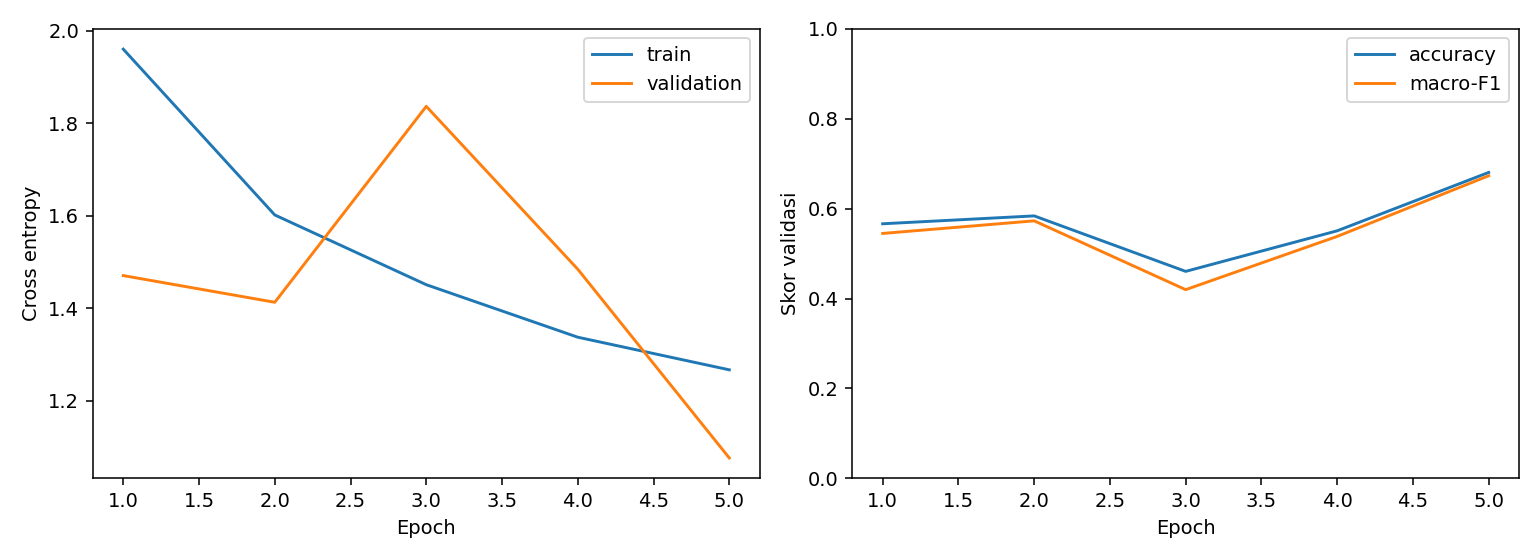

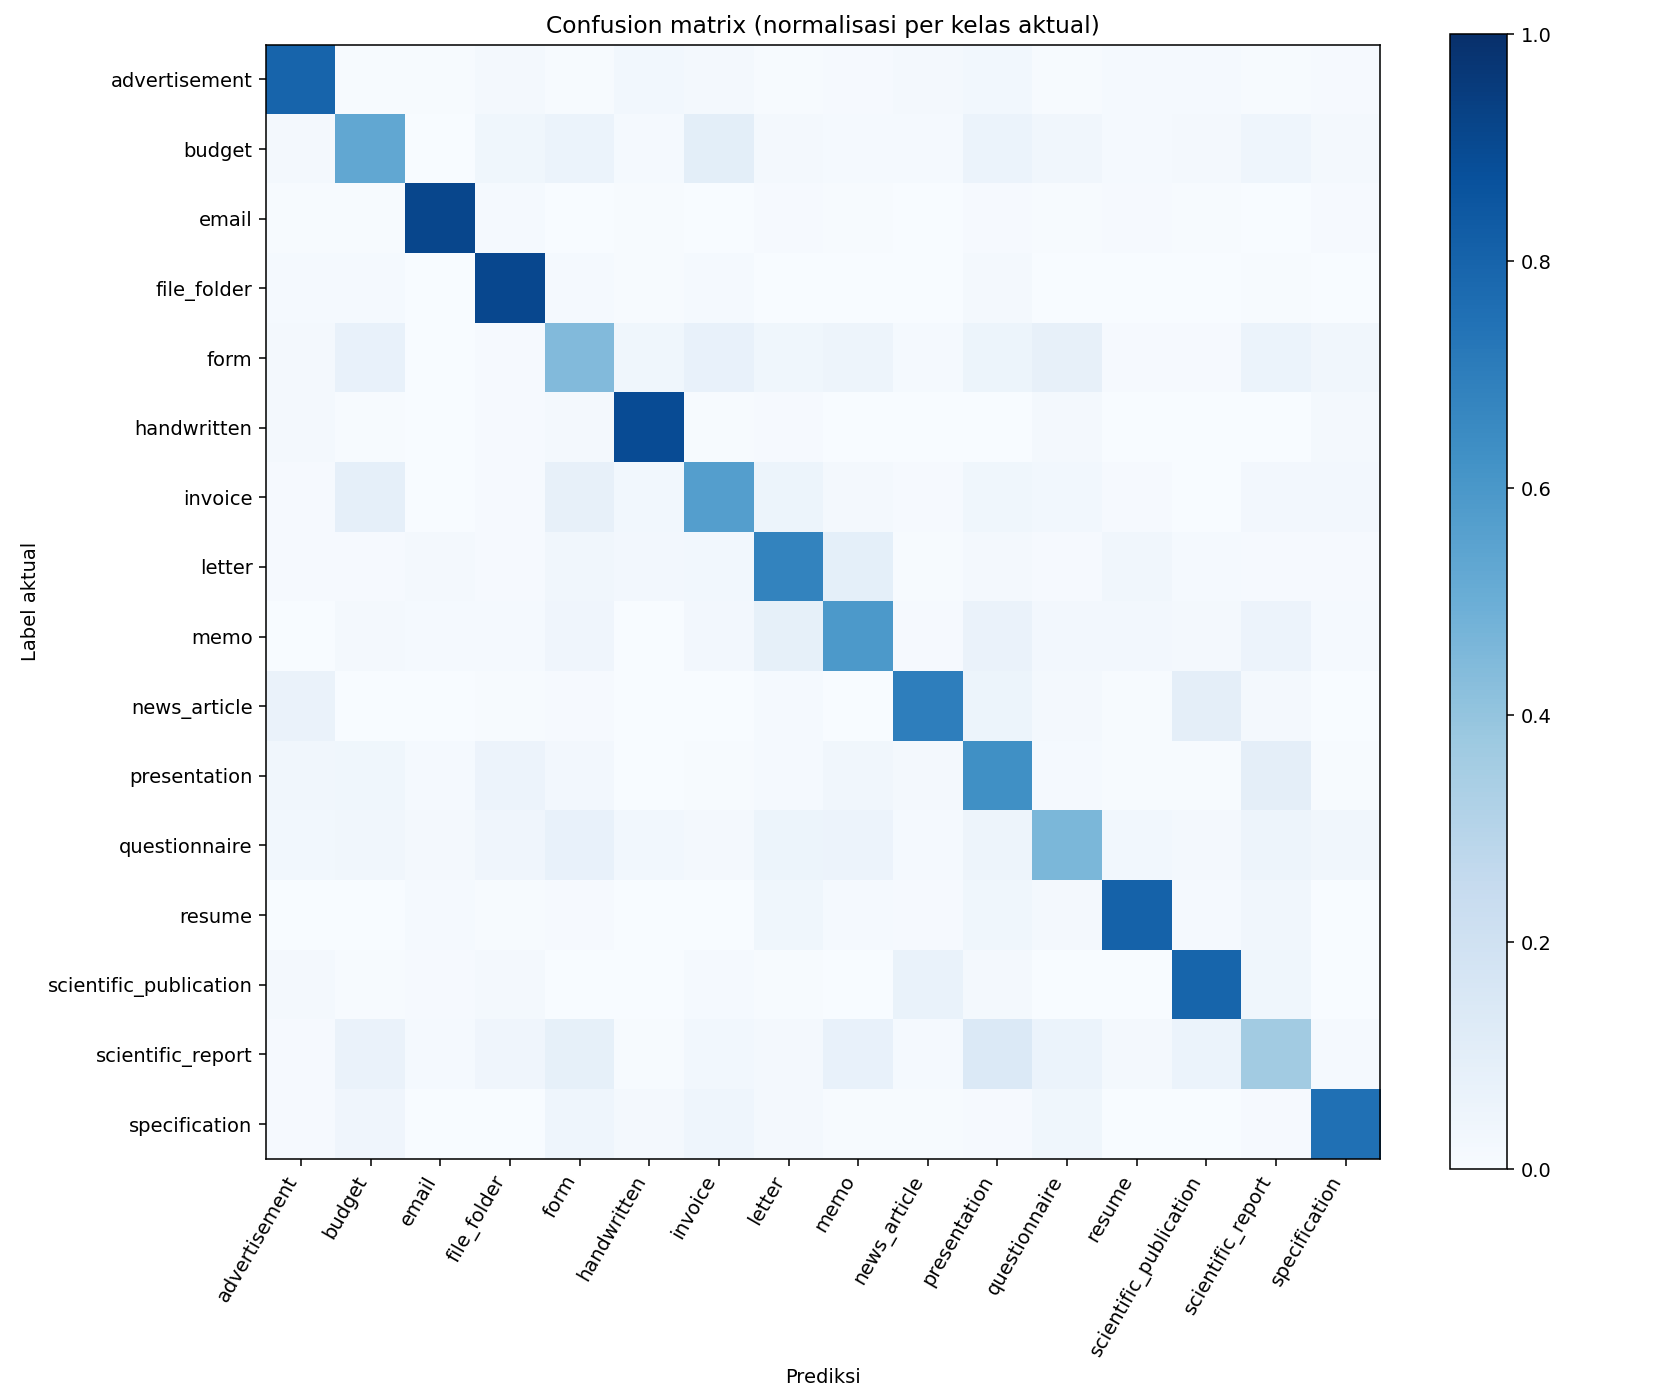

,precision,recall,f1-score,support
advertisement,0.755981,0.797980,0.776413,396.000000
budget,0.570637,0.529563,0.549333,389.000000
email,0.879093,0.911227,0.894872,383.000000
file_folder,0.770624,0.909739,0.834423,421.000000
form,0.451087,0.445040,0.448043,373.000000
handwritten,0.832285,0.892135,0.861171,445.000000
invoice,0.591781,0.568421,0.579866,380.000000
letter,0.625616,0.679144,0.651282,374.000000
memo,0.630380,0.590047,0.609547,422.000000
news_article,0.771831,0.698980,0.733601,392.000000


In [5]:
display(Image(filename=str(REPORT / 'learning_curves.png')))
display(Image(filename=str(REPORT / 'confusion_matrix.png')))
class_report = pd.DataFrame(metrics['classification_report']).T
display(class_report)

## Analisis kesalahan
Lihat kelas dengan F1 terendah dan prediksi salah dengan confidence tinggi. Kemiripan layout dapat menjadi hipotesis kesalahan; periksa halaman sumber sebelum menyimpulkan penyebab. Confidence softmax bukan probabilitas yang sudah dikalibrasi.

,precision,recall,f1-score,support
scientific_report,0.446809,0.359413,0.398374,409.0
form,0.451087,0.445040,0.448043,373.0
questionnaire,0.553459,0.458333,0.501425,384.0
budget,0.570637,0.529563,0.549333,389.0
presentation,0.512346,0.630380,0.565267,395.0


,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_27842,train/presentation/2061915920_2061915930.tif,presentation,10,0,advertisement,0.989317
1,train_09978,train/letter/528345909+-5909.tif,letter,7,2,email,0.986332
2,train_09099,train/scientific_report/50293315-3319.tif,scientific_report,14,12,resume,0.981652
3,train_27316,train/budget/2045814412_4416.tif,budget,1,10,presentation,0.981189
4,train_17566,train/scientific_report/2053453117.tif,scientific_report,14,15,specification,0.979197
5,train_14438,train/questionnaire/2041554137.tif,questionnaire,11,0,advertisement,0.977457
6,train_27418,train/budget/tob07122.45.tif,budget,1,6,invoice,0.974028
7,train_22810,train/letter/506900951.tif,letter,7,5,handwritten,0.973880
8,train_27612,train/memo/2076959185a.tif,memo,8,2,email,0.963408
9,train_04133,train/form/502012924.tif,form,4,15,specification,0.959340


train_27842: aktual=presentation, prediksi=advertisement, confidence=0.989


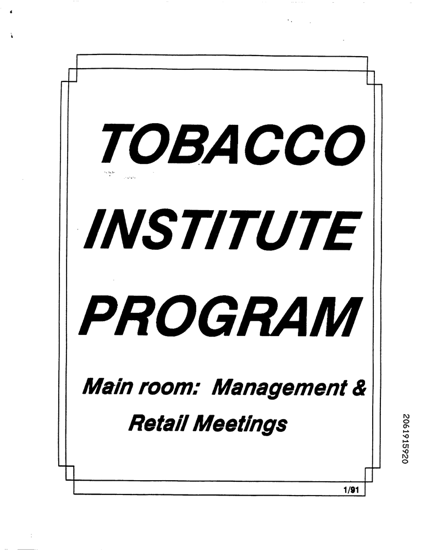

train_09978: aktual=letter, prediksi=email, confidence=0.986


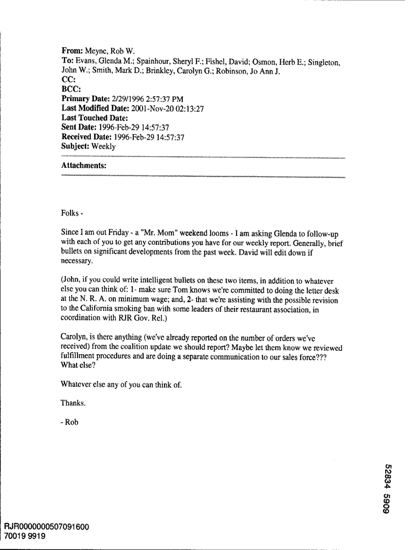

train_09099: aktual=scientific_report, prediksi=resume, confidence=0.982


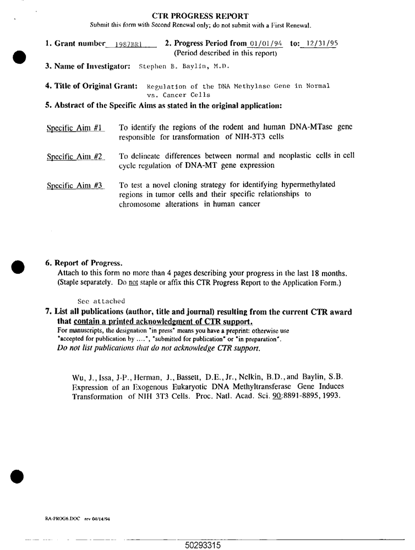

In [6]:
from scripts.preprocess import CLASSES, resolve_image
from PIL import Image as PILImage
display(class_report.loc[CLASSES].sort_values('f1-score').head(5))
errors = pd.read_csv(REPORT / 'confident_errors.csv')
display(errors.head(10))
for row in errors.head(3).itertuples():
    print(f'{row.id}: aktual={row.class_name}, prediksi={row.predicted_class}, confidence={row.confidence:.3f}')
    with PILImage.open(resolve_image(DATA, row.filename)) as page:
        preview = page.convert('RGB')
        preview.thumbnail((450, 550))
        display(preview)

## Eksperimen berikutnya
Jalankan konfigurasi EfficientNet pada GPU setelah baseline. Pertahankan split, bandingkan accuracy dan macro-F1, lalu putuskan berdasarkan metrik resmi kompetisi setelah tersedia. Resolusi 320 mempertahankan lebih banyak detail, tetapi keunggulannya harus dibuktikan lewat validasi. Hindari memakai bobot yang telah dilatih pada dataset dokumen kompetisi tanpa kepastian aturan dan pemisahan data. Public/private score hanya dicatat sesudah hasil resmi tersedia.